Resources for analysis:

* https://ucdavis-bioinformatics-training.github.io/2022-June-RNA-Seq-Analysis/data_analysis/DE_Analysis_mm_with_quizzes_fixed
* https://ucdavis-bioinformatics-training.github.io/2022-June-RNA-Seq-Analysis/data_reduction/03-counts_mm
* https://github.com/ben-laufer/RNA-seq/blob/main/04-limma-voom.R
* https://raw.githubusercontent.com/ucdavis-bioinformatics-training/2020-mRNA_Seq_Workshop/master/data_analysis/enrichment_mm.Rmd

I switched between batch 1 and 2 data by changing every instance of "batch1" to "batch2" and vice versa.

# Set Library Path

In [1]:
.libPaths("/home/vhaghani/anaconda3/envs/jupyter_nb_R4.4.2/lib/R/library")

# Load Libraries

In [3]:
library(edgeR)
library(rtracklayer)
library(gplots)
library(RColorBrewer)
library(dplyr)
library(ggplot2)

# Load Metadata

In [4]:
# Read in metadata
metadata <- read.csv("metadata.csv")

# Split metadata by gene to create named lists
metadata <- split(metadata, metadata$Gene)

# Remove any empty data frames that might result from filtering
metadata <- metadata[sapply(metadata, nrow) > 0]

# View
str(metadata)

List of 1
 $ MECP2:'data.frame':	32 obs. of  21 variables:
  ..$ Gene                      : chr [1:32] "MECP2" "MECP2" "MECP2" "MECP2" ...
  ..$ Sample_ID                 : chr [1:32] "KB1" "KB2" "KB3" "KB4" ...
  ..$ Sample_Name               : chr [1:32] "CO_R270X_B1_d18_A1" "CO_R270X_B1_d18_A2" "CO_R270X_B1_d18_A3" "CO_R270X_B1_d18_D1" ...
  ..$ Cell_Type                 : chr [1:32] "Cerebral_Organoid" "Cerebral_Organoid" "Cerebral_Organoid" "Cerebral_Organoid" ...
  ..$ Genotype                  : chr [1:32] "MUT" "MUT" "MUT" "WT" ...
  ..$ Time_Point                : chr [1:32] "D18" "D18" "D18" "D18" ...
  ..$ Group                     : chr [1:32] "R270X_D18" "R270X_D18" "R270X_D18" "WT_D18" ...
  ..$ Batch                     : int [1:32] 0 0 0 0 0 0 0 0 0 0 ...
  ..$ D18_MUT_vs_D18_WT         : int [1:32] 1 1 1 0 0 0 NA NA NA NA ...
  ..$ D46_MUT_vs_D46_WT         : int [1:32] NA NA NA NA NA NA 1 1 1 0 ...
  ..$ D90_MUT_vs_D90_WT         : int [1:32] NA NA NA NA NA NA NA NA 

In [5]:
# View groups 
for (gene_name in names(metadata)) {
  cat("\n=== Group counts for", gene_name, "===\n")
  print(table(metadata[[gene_name]]$Group))
}


=== Group counts for MECP2 ===

R270X_D18 R270X_D46 R270X_D90    WT_D18    WT_D46    WT_D90 
        6         4         6         6         5         5 


# Load Counts

In [6]:
# Read in counts
counts <- read.delim("05_gene_counts/hgnc_counts.txt")

# Assign rownames
rownames(counts) <- counts$gene_id
counts$gene_id <- NULL

# View
head(counts)

,gene_symbol,KB1,KB10,KB11,KB12,KB13,KB14,KB15,KB16,KB17,⋯,KB31,KB32,KB33,KB34,KB4,KB5,KB6,KB7,KB8,KB9
,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,A0A024QYX8,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
2,A0A024QZ33,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
3,A0A024QZ42,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
4,A0A024QZB8,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
5,A0A024QZC2,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
6,A0A024QZE4,1,0,0,0,0,0,0,0,0,⋯,1,0,2,1,1,0,0,0,0,0


In [8]:
# Read in metadata and select only the mapping columns to rename samples
mapping_df <- read.csv("metadata.csv")[, c("Sample_ID", "Sample_Name")]

# Create mapping
name_mapping <- setNames(mapping_df$Sample_Name, mapping_df$Sample_ID)

# Remove whitespace
colnames(counts) <- trimws(colnames(counts))

# Rename columns
colnames(counts) <- name_mapping[colnames(counts)]

# Drop columns that don't map
counts <- counts[, !is.na(colnames(counts))]

# View
head(counts)

,CO_R270X_B1_d18_A1,CO_R270X_B1_d46_D1,CO_R270X_B1_d46_D2,CO_R270X_B1_d46_D3,CO_R270X_B1_d90_A1,CO_R270X_B1_d90_A2,CO_R270X_B1_d90_A3,CO_R270X_B1_d90_D1,CO_R270X_B1_d90_D2,CO_R270X_B1_d90_D3,⋯,CO_R270X_B2_d90_A2,CO_R270X_B2_d90_A3,CO_R270X_B2_d90_D2,CO_R270X_B2_d90_D3,CO_R270X_B1_d18_D1,CO_R270X_B1_d18_D2,CO_R270X_B1_d18_D3,CO_R270X_B1_d46_A1,CO_R270X_B1_d46_A2,CO_R270X_B1_d46_A3
,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
6,1,0,0,0,0,0,0,0,0,0,⋯,1,0,2,1,1,0,0,0,0,0


# Create DEG Objects

In [20]:
# Create objects for each gene
gene_analysis_objects <- lapply(names(metadata), function(gene_name) {
  gene_meta <- metadata[[gene_name]]
  gene_samples <- gene_meta$Sample_Name
  
  # Get counts for this gene's samples
  gene_counts <- counts[, colnames(counts) %in% gene_samples, drop = FALSE]
  
  # Ensure counts and metadata are in the same order
  gene_counts <- gene_counts[, gene_meta$Sample_Name, drop = FALSE]
  
  # Create design matrix for differential expression analysis
  design <- model.matrix(~ 0 + Group + Batch, data = gene_meta)
  colnames(design) <- gsub("group", "", colnames(design))
  
  list(
    counts = gene_counts,
    metadata = gene_meta,
    design = design,
    group_counts = table(gene_meta$Group),
    sample_order = gene_meta$Sample_Name
  )
})

# Assign gene names to DEG list object
names(gene_analysis_objects) <- names(metadata)

In [21]:
# Verify that counts and metadata are properly aligned for each gene
for (Gene in names(gene_analysis_objects)) {
  obj <- gene_analysis_objects[[Gene]]
  cat("\n=== Gene:", Gene, "===")
  cat("\nCounts columns:", colnames(obj$counts))
  cat("\nMetadata samples:", obj$metadata$Sample_Name)
  cat("\nMatch:", identical(colnames(obj$counts), obj$metadata$Sample_Name))
  cat("\n")
}


=== Gene: MECP2 ===
Counts columns: CO_R270X_B1_d18_A1 CO_R270X_B1_d18_A2 CO_R270X_B1_d18_A3 CO_R270X_B1_d18_D1 CO_R270X_B1_d18_D2 CO_R270X_B1_d18_D3 CO_R270X_B1_d46_A1 CO_R270X_B1_d46_A2 CO_R270X_B1_d46_A3 CO_R270X_B1_d46_D1 CO_R270X_B1_d46_D2 CO_R270X_B1_d46_D3 CO_R270X_B1_d90_A1 CO_R270X_B1_d90_A2 CO_R270X_B1_d90_A3 CO_R270X_B1_d90_D1 CO_R270X_B1_d90_D2 CO_R270X_B1_d90_D3 CO_R270X_B2_d18_A1 CO_R270X_B2_d18_A2 CO_R270X_B2_d18_A3 CO_R270X_B2_d18_D1 CO_R270X_B2_d18_D2 CO_R270X_B2_d18_D3 CO_R270X_B2_d46_A3 CO_R270X_B2_d46_D1 CO_R270X_B2_d46_D2 CO_R270X_B2_d90_A1 CO_R270X_B2_d90_A2 CO_R270X_B2_d90_A3 CO_R270X_B2_d90_D2 CO_R270X_B2_d90_D3
Metadata samples: CO_R270X_B1_d18_A1 CO_R270X_B1_d18_A2 CO_R270X_B1_d18_A3 CO_R270X_B1_d18_D1 CO_R270X_B1_d18_D2 CO_R270X_B1_d18_D3 CO_R270X_B1_d46_A1 CO_R270X_B1_d46_A2 CO_R270X_B1_d46_A3 CO_R270X_B1_d46_D1 CO_R270X_B1_d46_D2 CO_R270X_B1_d46_D3 CO_R270X_B1_d90_A1 CO_R270X_B1_d90_A2 CO_R270X_B1_d90_A3 CO_R270X_B1_d90_D1 CO_R270X_B1_d90_D2 CO_R270X_B1_d9

# DEG Analysis

In [22]:
# Box plots to assess data filering
for (gene_name in names(gene_analysis_objects)) {
  cat("\n=== Processing gene:", gene_name, "===\n")
  
  # Get the analysis object for this gene
  gene_obj <- gene_analysis_objects[[gene_name]]
  
  # Create DEG list
  d0 <- DGEList(gene_obj$counts)
  
  # Preprocess and normalize
  d0 <- calcNormFactors(d0)
  
  # --- PRE-FILTERING: compute CPMs BEFORE filtering ---
  cpm_pre <- cpm(d0)
  
  # Filter genes by expression
  keep <- filterByExpr(d0, gene_obj$design)
  cat("Genes retained after filtering:", sum(keep), "\n")
  d <- d0[keep, ]
    
  cat("Genes retained after filtering:", sum(keep), "\n")
  
  d <- d0[keep, ]
  
  # --- POST-FILTERING: compute CPMs AFTER filtering ---
  cpm_post <- cpm(d)
  
  # Save boxplots: pre- and post-filtering
  pdf(paste0("05_DEGs/cpm_boxplots_batch1.pdf"), height = 9, width = 12)
  par(mfrow = c(1, 2), mar = c(12, 4, 4, 2))
  
  # Pre-filtering
  boxplot(cpm_pre, outline = FALSE, main = "Pre-filtering CPMs", xaxt = "n")
  axis(1, at = 1:ncol(cpm_pre), labels = colnames(cpm_pre), las = 2, cex.axis = 0.7)
  
  # Post-filtering
  boxplot(cpm_post, outline = FALSE, main = "Post-filtering CPMs", xaxt = "n")
  axis(1, at = 1:ncol(cpm_post), labels = colnames(cpm_post), las = 2, cex.axis = 0.7)
  
  dev.off()
}


=== Processing gene: MECP2 ===
Genes retained after filtering: 19577 
Genes retained after filtering: 19577 



=== Processing gene: MECP2 ===
Genes retained after filtering: 19577 
Unique groups: R270X_D18, WT_D18, R270X_D46, WT_D46, R270X_D90, WT_D90 
Design matrix columns: R270X_D18, R270X_D46, R270X_D90, WT_D18, WT_D46, WT_D90, Batch 
  Comparison: R270X_D18 vs WT_D18 
    DEGs (adj.P.Val < 0.05): 130 
  Comparison: R270X_D18 vs R270X_D46 
    DEGs (adj.P.Val < 0.05): 9275 
  Comparison: R270X_D18 vs WT_D46 
    DEGs (adj.P.Val < 0.05): 9315 
  Comparison: R270X_D18 vs R270X_D90 
    DEGs (adj.P.Val < 0.05): 11725 
  Comparison: R270X_D18 vs WT_D90 
    DEGs (adj.P.Val < 0.05): 11562 
  Comparison: WT_D18 vs R270X_D46 
    DEGs (adj.P.Val < 0.05): 9422 
  Comparison: WT_D18 vs WT_D46 
    DEGs (adj.P.Val < 0.05): 9438 
  Comparison: WT_D18 vs R270X_D90 
    DEGs (adj.P.Val < 0.05): 11704 
  Comparison: WT_D18 vs WT_D90 
    DEGs (adj.P.Val < 0.05): 11475 
  Comparison: R270X_D46 vs WT_D46 
    DEGs (adj.P.Val < 0.05): 91 
  Comparison: R270X_D46 vs R270X_D90 
    DEGs (adj.P.Val < 0.05): 49

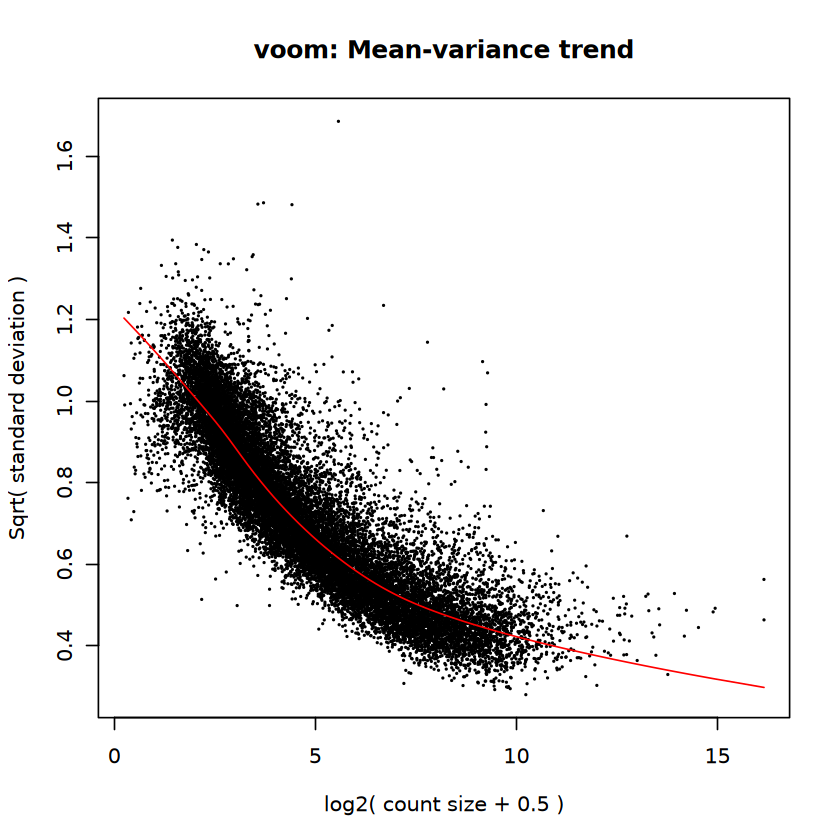

In [25]:
# Loop through each gene in gene_analysis_objects
for (gene_name in names(gene_analysis_objects)) {
  cat("\n=== Processing gene:", gene_name, "===\n")
  
  # Get the analysis object for this gene
  gene_obj <- gene_analysis_objects[[gene_name]]
  
  # Create DEG list
  d0 <- DGEList(gene_obj$counts)
  
  # Preprocess and normalize
  d0 <- calcNormFactors(d0)
  
  # Filter genes by expression
  keep <- filterByExpr(d0, gene_obj$design)
  cat("Genes retained after filtering:", sum(keep), "\n")
  d <- d0[keep, ]
    
  # Obtain log-transformed normalized expression data
  logcpm <- cpm(d, prior.count = 2, log = TRUE)
  write.table(logcpm, 
              paste0("05_gene_counts/", gene_name, "_normalized_counts.txt"),
              sep = "\t", quote = FALSE)
  
  # Clean up design matrix column names
  colnames(gene_obj$design) <- gsub("^Group", "", colnames(gene_obj$design))
  
  # Voom transformation
  y <- voom(d, gene_obj$design, plot = TRUE)
  
  # Fit linear model
  fit <- lmFit(y, gene_obj$design)
  
  # Get all unique groups for this gene
  unique_groups <- unique(gene_obj$metadata$Group)
  cat("Unique groups:", paste(unique_groups, collapse = ", "), "\n")
  cat("Design matrix columns:", paste(colnames(gene_obj$design), collapse = ", "), "\n")
  
  # Generate all possible pairwise comparisons
  if (length(unique_groups) > 1) {
    comparisons <- combn(unique_groups, 2, simplify = FALSE)
  
    # Loop through each pairwise comparison
    for (comparison in comparisons) {
      group1 <- comparison[1]
      group2 <- comparison[2]
      
      cat("  Comparison:", group1, "vs", group2, "\n")
      
      # Define contrast using exact group names
      contr <- makeContrasts(
        contrasts = paste0(group1, "-", group2),
        levels = gene_obj$design
      )
      
      # Estimate contrast for each gene
      tmp <- contrasts.fit(fit, contr)
      
      # Apply eBayes
      tmp <- eBayes(tmp)
      
      # Get results with multiple testing adjustment
      top.table <- topTable(tmp, adjust.method = "BH", sort.by = "P", n = Inf)
      
      # Count significant DEGs
      num_degs <- sum(top.table$adj.P.Val < 0.05)
      cat("    DEGs (adj.P.Val < 0.05):", num_degs, "\n")
      
      # Save results
      write.csv(top.table, 
                file = paste0("05_DEGs/", group1, "_vs_", group2, "_results.csv"),
                row.names = TRUE)
    }
  } else {
    cat("  Only one group found, skipping pairwise comparisons\n")
  }
}